In [23]:
# 1. Import Libraries
from torchvision import datasets # ImageFolder loads images from class folders
import torchvision.transforms as transforms # image preprocessing and augmentation

from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [2]:
# 2. Load Dataset
import kagglehub
path = kagglehub.dataset_download("gpiosenka/sports-classification") # downloaded dataset from Kaggle
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'sports-classification' dataset.
Path to dataset files: /kaggle/input/sports-classification


In [21]:
# 3. Preprocessing

import torchvision.transforms as transforms

size = 32 # all images are resized to size x size
train_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

train_folder = path+'/train'
val_folder = path+'/valid'
test_folder = path+'/test'

train_data = datasets.ImageFolder(train_folder, transform = train_transform)
val_data = datasets.ImageFolder(val_folder, transform = val_transform)
test_data = datasets.ImageFolder(test_folder, transform = val_transform)

In [17]:
print('Dataset Summary')
print('Train Data: ', len(train_data))
print('Validation Data: ', len(val_data))
print('Test Data: ', len(test_data))
print('Number of Classes: ', len(train_data.classes))
print('Classess and Indices: ' , train_data.class_to_idx)

Dataset Summary
Train Data:  13492
Validation Data:  500
Test Data:  500
Number of Classes:  100
Classess and Indices:  {'air hockey': 0, 'ampute football': 1, 'archery': 2, 'arm wrestling': 3, 'axe throwing': 4, 'balance beam': 5, 'barell racing': 6, 'baseball': 7, 'basketball': 8, 'baton twirling': 9, 'bike polo': 10, 'billiards': 11, 'bmx': 12, 'bobsled': 13, 'bowling': 14, 'boxing': 15, 'bull riding': 16, 'bungee jumping': 17, 'canoe slamon': 18, 'cheerleading': 19, 'chuckwagon racing': 20, 'cricket': 21, 'croquet': 22, 'curling': 23, 'disc golf': 24, 'fencing': 25, 'field hockey': 26, 'figure skating men': 27, 'figure skating pairs': 28, 'figure skating women': 29, 'fly fishing': 30, 'football': 31, 'formula 1 racing': 32, 'frisbee': 33, 'gaga': 34, 'giant slalom': 35, 'golf': 36, 'hammer throw': 37, 'hang gliding': 38, 'harness racing': 39, 'high jump': 40, 'hockey': 41, 'horse jumping': 42, 'horse racing': 43, 'horseshoe pitching': 44, 'hurdles': 45, 'hydroplane racing': 46, 'ic

In [24]:
# Hyperparameters
batch_size = 32
learning_rate=1e-3
epoch_number = 10
num_classes = len(train_data.classes)

In [6]:
trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

In [25]:
from torch.optim import SGD, Adam
def get_model():
    model = nn.Sequential(
        #Feature Extraction
        nn.Conv2d(3, 64, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(64, 128, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),

        #Classifier
        nn.Flatten(),
        nn.Linear(128*6*6, 256),
        nn.ReLU(),
        nn.Linear(256, num_classes)
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

In [22]:

# Training and validation functions
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

In [18]:
!pip install torchsummary -q
from torchsummary import summary
model, loss_fn, optimizer = get_model()
summary(model, input_size=(3,32,32));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 30, 30]           1,792
              ReLU-2           [-1, 64, 30, 30]               0
         MaxPool2d-3           [-1, 64, 15, 15]               0
            Conv2d-4          [-1, 128, 13, 13]          73,856
              ReLU-5          [-1, 128, 13, 13]               0
         MaxPool2d-6            [-1, 128, 6, 6]               0
           Flatten-7                 [-1, 4608]               0
            Linear-8                  [-1, 256]       1,179,904
              ReLU-9                  [-1, 256]               0
           Linear-10                  [-1, 100]          25,700
Total params: 1,281,252
Trainable params: 1,281,252
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 1.39
Params size (MB): 4.89
Estimat

In [10]:
#Training Loop
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(epoch_number):
  epoch_loss, epoch_accuracy = train_one_epoch(trn_dl,model,loss_fn,optimizer)
  train_losses.append(epoch_loss)
  train_accuracies.append(epoch_accuracy)

  v_loss, v_acc =  validation(val_dl,model,loss_fn)
  val_losses.append(v_loss)
  val_accuracies.append(v_acc)

  print(f"Epoch [{epoch + 1}/{epoch_number}]"
        f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
        f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

Epoch [1/10] | Train Loss: 4.1219 | Train Accuracy: 6.91% | Val Loss: 3.6165 | Val Accuracy: 12.40%
Epoch [2/10] | Train Loss: 3.4571 | Train Accuracy: 16.60% | Val Loss: 3.1895 | Val Accuracy: 23.60%
Epoch [3/10] | Train Loss: 3.1288 | Train Accuracy: 22.23% | Val Loss: 2.8831 | Val Accuracy: 28.60%
Epoch [4/10] | Train Loss: 2.9147 | Train Accuracy: 27.06% | Val Loss: 2.7268 | Val Accuracy: 33.60%
Epoch [5/10] | Train Loss: 2.7559 | Train Accuracy: 30.12% | Val Loss: 2.6699 | Val Accuracy: 36.00%
Epoch [6/10] | Train Loss: 2.6125 | Train Accuracy: 33.28% | Val Loss: 2.5689 | Val Accuracy: 36.00%
Epoch [7/10] | Train Loss: 2.4953 | Train Accuracy: 35.76% | Val Loss: 2.4840 | Val Accuracy: 36.40%
Epoch [8/10] | Train Loss: 2.3940 | Train Accuracy: 37.99% | Val Loss: 2.4343 | Val Accuracy: 38.80%
Epoch [9/10] | Train Loss: 2.2984 | Train Accuracy: 39.87% | Val Loss: 2.4295 | Val Accuracy: 38.80%
Epoch [10/10] | Train Loss: 2.2274 | Train Accuracy: 41.51% | Val Loss: 2.4050 | Val Accurac

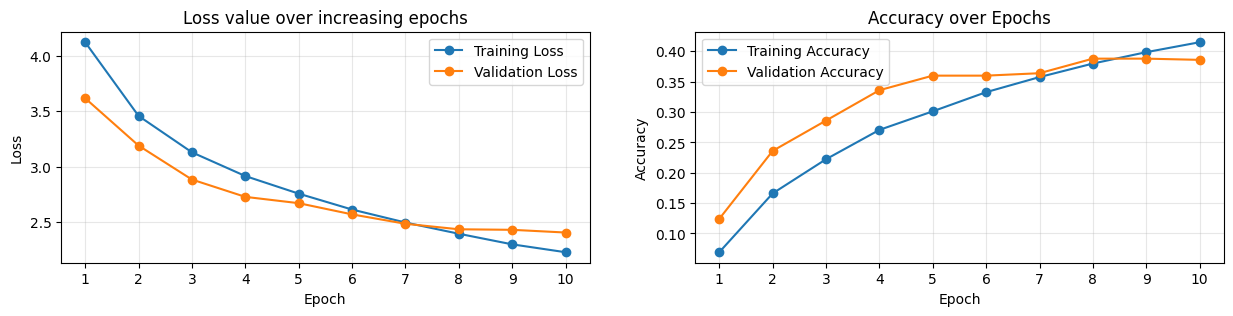

In [11]:
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 3))
plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

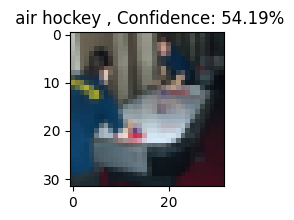

In [12]:
test_img, label = test_data[2]
img = test_img.view(-1,3,size,size).to(device)

output = model(img)
pred = torch.exp(output)/torch.sum(torch.exp(output))
confidence, index  = pred.max(-1)

plt.figure(figsize=(2,2))
plt.imshow(test_img.view(3,size,size).permute(1,2,0))
plt.title(f' {train_data.classes[index]} , Confidence: {confidence.item()*100:0.2f}%')
plt.show()

In [13]:
test_loss, test_acc =  validation(test_dl,model,loss_fn)
print(f'Test Loss : {test_loss:0.2f} , Test Accuracy: {test_acc*100:0.2f}%')

Test Loss : 2.24 , Test Accuracy: 43.20%


In [14]:
torch.save(model.state_dict(),'model.pth')

In [15]:
saved_model = get_model()[0]
saved_model.load_state_dict(torch.load('model.pth'))
saved_model.eval()
summary(saved_model,(3,32,32))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 30, 30]           1,792
              ReLU-2           [-1, 64, 30, 30]               0
         MaxPool2d-3           [-1, 64, 15, 15]               0
            Conv2d-4          [-1, 128, 13, 13]          73,856
              ReLU-5          [-1, 128, 13, 13]               0
         MaxPool2d-6            [-1, 128, 6, 6]               0
           Flatten-7                 [-1, 4608]               0
            Linear-8                  [-1, 256]       1,179,904
              ReLU-9                  [-1, 256]               0
           Linear-10                  [-1, 100]          25,700
Total params: 1,281,252
Trainable params: 1,281,252
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 1.39
Params size (MB): 4.89
Estimat

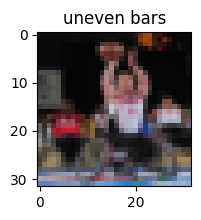

Actual class: wheelchair basketball


In [16]:
@torch.no_grad()
def predictOne(model,img,classes = None):
  model.eval()
  img = img.view(-1,3,size,size).to(device)
  np_output = model(img).cpu().detach().numpy()
  pred = np.exp(np_output)/np.sum(np.exp(np_output))
  plt.figure(figsize=(2,2))
  plt.imshow(img.view(3,size,size).permute(1,2,0).cpu().detach().numpy())
  plt.title(classes[pred.argmax()]) if classes is not None else plt.title(pred.argmax())
  plt.show()

img , label = test_data[np.random.randint(0,len(test_data))]
predictOne(saved_model, img, train_data.classes)
print('Actual class:', train_data.classes[label])